# Caffeine

In [2]:
import pandas as pd

## 1. Analiza danych

### 1. Wczytanie pliku CSV do ramki danych

In [3]:
df = pd.read_csv('caffeine_crash_and_anxiety_telemetry.csv')

### 2. Sprawdzenie rozmiaru tabeli

In [4]:
print(f"Liczba wierszy (próbek): {df.shape[0]}")
print(f"Liczba kolumn (cech): {df.shape[1]}")

Liczba wierszy (próbek): 8000
Liczba kolumn (cech): 18


### 3. Wyświetlenie pierwszych 5 wierszy

In [5]:
display(df.head())

,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.4,7.0,2.29,Brewed Drip Coffee,138,8.7,36,2.0,1.0,1.0,7.5,4.1,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.1,7.1,2.41,Energy Drink (Sugar-Free),164,0.0,3,2.4,2.0,5.5,7.5,2.5,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.9,5.1,2.07,Energy Drink (Full Sugar),179,36.9,10,3.8,4.8,5.5,3.6,7.9,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.8,5.0,2.34,Pre-Workout Supplement,408,1.6,3,6.8,4.2,7.3,7.5,10.0,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.0,6.3,1.92,Energy Drink (Full Sugar),170,50.2,11,2.0,2.0,1.1,2.6,10.0,Severe Crash & Tachycardia


### 4. Mapowanie słownika 

In [62]:
slownik_tlumaczen = {
    'user_id': 'id_uzytkownika',
    'age': 'wiek',
    'gender': 'plec',
    'cyp1a2_metabolizer_type': 'typ_metabolizmu_cyp1a2',
    'caffeine_tolerance': 'tolerancja_kofeiny',
    'baseline_anxiety_score': 'bazowy_poziom_leku',
    'prior_sleep_hours': 'godziny_snu',
    'daily_hydration_liters': 'dzienne_nawodnienie_litry',
    'primary_caffeine_source': 'zrodlo_kofeiny',
    'caffeine_mg': 'kofeina_mg',
    'sugar_grams': 'cukier_gramy',
    'consumption_duration_min': 'czas_konsumpcji_min',
    'heart_rate_spike_bpm': 'skok_tetna_bpm',
    'jitters_intensity_score': 'intensywnosc_drzawek',
    'acute_anxiety_score': 'ostry_poziom_leku',
    'crash_onset_hours': 'czas_do_zjazdu_godziny',
    'crash_severity_score': 'nasilenie_zjazdu',
    'crash_risk_level': 'poziom_ryzyka_zjazdu'
}

mapowanie_zjazdu = {
    'Mild Afternoon Fatigue': 'Łagodne popołudniowe zmęczenie',
    'Sustained / Negligible Crash': 'Stabilny stan / Znikomy zjazd',
    'Moderate Crash & Lethargy': 'Umiarkowany zjazd i letarg',
    'Severe Crash & Tachycardia': 'Ciężki zjazd i tachykardia'
}

#### Zmiana nazw kolumn w tabeli df

In [57]:
df = df.rename(columns=slownik_tlumaczen)
df['poziom_ryzyka_zjazdu'] = df['poziom_ryzyka_zjazdu'].map(mapowanie_zjazdu)

#### Sprawdzenie, czy kolumny zostały zmienione

In [28]:
print("Nowe polskie nazwy kolumn:")
print(df.columns.tolist())

Nowe polskie nazwy kolumn:
['id_uzytkownika', 'wiek', 'plec', 'typ_metabolizmu_cyp1a2', 'tolerancja_kofeiny', 'bazowy_poziom_leku', 'godziny_snu', 'dzienne_nawodnienie_litry', 'zrodlo_kofeiny', 'kofeina_mg', 'cukier_gramy', 'czas_konsumpcji_min', 'skok_tetna_bpm', 'intensywnosc_drzawek', 'ostry_poziom_leku', 'czas_do_zjazdu_godziny', 'nasilenie_zjazdu', 'poziom_ryzyka_zjazdu']


### 5. Sprawdzenie typów danych oraz ewentualnych braków

In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_uzytkownika             8000 non-null   str    
 1   wiek                       8000 non-null   int64  
 2   plec                       8000 non-null   str    
 3   typ_metabolizmu_cyp1a2     8000 non-null   str    
 4   tolerancja_kofeiny         8000 non-null   str    
 5   bazowy_poziom_leku         8000 non-null   float64
 6   godziny_snu                8000 non-null   float64
 7   dzienne_nawodnienie_litry  8000 non-null   float64
 8   zrodlo_kofeiny             8000 non-null   str    
 9   kofeina_mg                 8000 non-null   int64  
 10  cukier_gramy               8000 non-null   float64
 11  czas_konsumpcji_min        8000 non-null   int64  
 12  skok_tetna_bpm             8000 non-null   float64
 13  intensywnosc_drzawek       8000 non-null   float64
 14  ost

### 6. Sprawdzenie duplikatów

In [31]:
duplikaty_liczba = df.duplicated().sum()
print(f"Liczba wierszy zduplikowanych w całej tabeli: {duplikaty_liczba}")

Liczba wierszy zduplikowanych w całej tabeli: 0


### 7. Sprawdzenie braków danych

In [32]:
brakujące_dane = df.isnull().sum()
print("\nLiczba braków danych w poszczególnych kolumnach:")
print(brakujące_dane[brakujące_dane > 0])


Liczba braków danych w poszczególnych kolumnach:
Series([], dtype: int64)


### 8. Sprawdzenie wartości odstajacych (metoda IQR - rozstęp ćwiartkowy)

In [33]:
print("\nAnaliza wartości odstających kolumnach liczbowych:")
kolumny_numeryczne = df.select_dtypes(include=['int64', 'float64']).columns

for kolumna in kolumny_numeryczne:
    Q1 = df[kolumna].quantile(0.25)
    Q3 = df[kolumna].quantile(0.75)
    IQR = Q3 - Q1
    dolna_granica = Q1 - 1.5 * IQR
    gorna_granica = Q3 + 1.5 * IQR

    odstajace = df[(df[kolumna] < dolna_granica) | (df[kolumna] > gorna_granica)]
    print(f" - Kolumna '{kolumna}': znaleziono {len(odstajace)} wartości odstających.")


Analiza wartości odstających kolumnach liczbowych:
 - Kolumna 'wiek': znaleziono 38 wartości odstających.
 - Kolumna 'bazowy_poziom_leku': znaleziono 243 wartości odstających.
 - Kolumna 'godziny_snu': znaleziono 0 wartości odstających.
 - Kolumna 'dzienne_nawodnienie_litry': znaleziono 21 wartości odstających.
 - Kolumna 'kofeina_mg': znaleziono 283 wartości odstających.
 - Kolumna 'cukier_gramy': znaleziono 0 wartości odstających.
 - Kolumna 'czas_konsumpcji_min': znaleziono 2 wartości odstających.
 - Kolumna 'skok_tetna_bpm': znaleziono 424 wartości odstających.
 - Kolumna 'intensywnosc_drzawek': znaleziono 228 wartości odstających.
 - Kolumna 'ostry_poziom_leku': znaleziono 0 wartości odstających.
 - Kolumna 'czas_do_zjazdu_godziny': znaleziono 0 wartości odstających.
 - Kolumna 'nasilenie_zjazdu': znaleziono 0 wartości odstających.


## 2. Wizualizacja

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
sns.set_theme(style="whitegrid")

#### WYKRES 1: Macierz korelacji (Mapa ciepła)

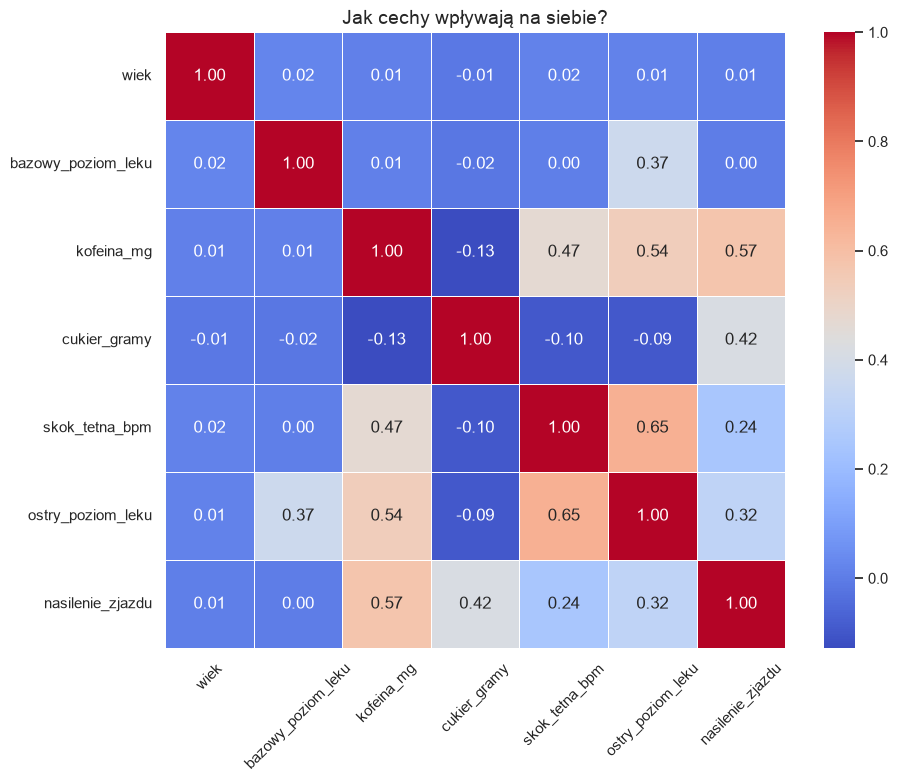

In [58]:
plt.figure(figsize=(10, 8))
kolumny_do_korelacji = ['wiek', 'bazowy_poziom_leku', 'kofeina_mg', 'cukier_gramy', 
                        'skok_tetna_bpm', 'ostry_poziom_leku', 'nasilenie_zjazdu']
kor = df[kolumny_do_korelacji].corr()

sns.heatmap(kor, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Jak cechy wpływają na siebie?", fontsize=14)
plt.xticks(rotation=45)
plt.show()

#### WYKRES 2: Dawka kofeiny a skok tętna (Punktowy)

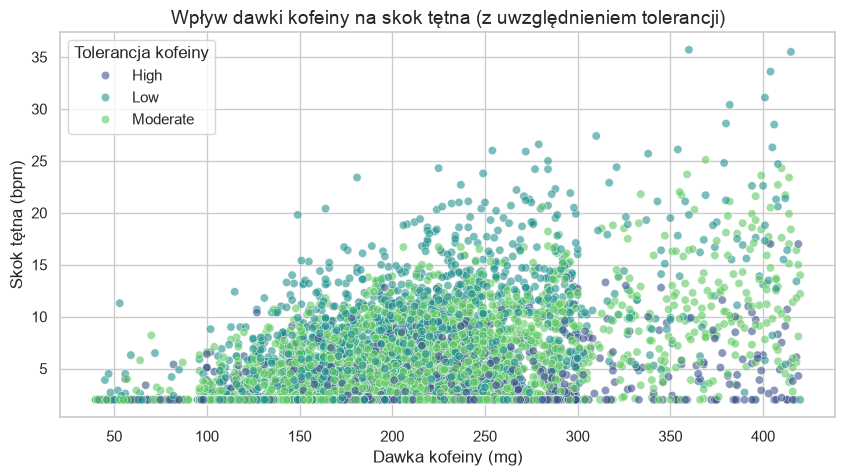

In [59]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='kofeina_mg', y='skok_tetna_bpm', hue='tolerancja_kofeiny', alpha=0.6, palette='viridis')
plt.title("Wpływ dawki kofeiny na skok tętna (z uwzględnieniem tolerancji)", fontsize=14)
plt.xlabel("Dawka kofeiny (mg)")
plt.ylabel("Skok tętna (bpm)")
plt.legend(title="Tolerancja kofeiny")
plt.show()

#### WYKRES 3: Poziom lęku a ryzyko zjazdu (Pudełkowy)

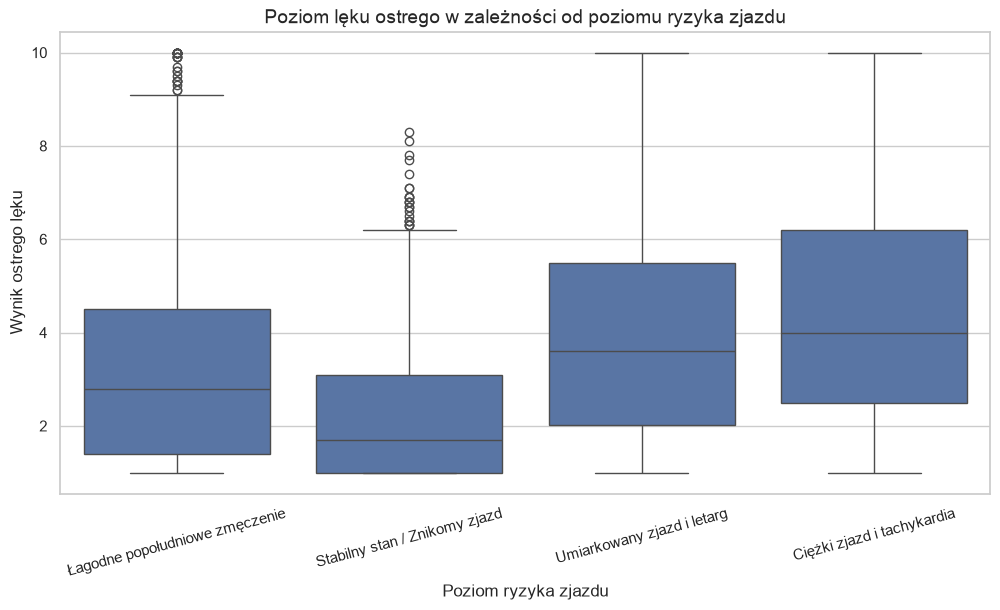

In [60]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='poziom_ryzyka_zjazdu', y='ostry_poziom_leku')
plt.xticks(rotation=15)
plt.title("Poziom lęku ostrego w zależności od poziomu ryzyka zjazdu", fontsize=14)
plt.xlabel("Poziom ryzyka zjazdu")
plt.ylabel("Wynik ostrego lęku")
plt.show()

#### WYKRES 4: Dawka kofeiny a typ metabolizmu (Skrzypcowy)

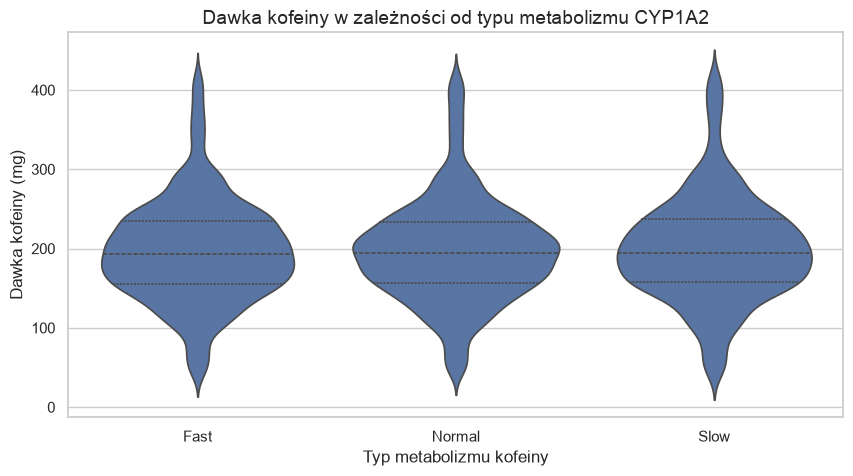

In [63]:
plt.figure(figsize=(10, 5))
sns.violinplot(data=df, x='typ_metabolizmu_cyp1a2', y='kofeina_mg', inner='quartile')
plt.title("Dawka kofeiny w zależności od typu metabolizmu CYP1A2", fontsize=14)
plt.xlabel("Typ metabolizmu kofeiny")
plt.ylabel("Dawka kofeiny (mg)")
plt.show()

#### WYKRES 5. Główne źródło kofeiny a poziom ryzyka zjazdu (Słupkowy)

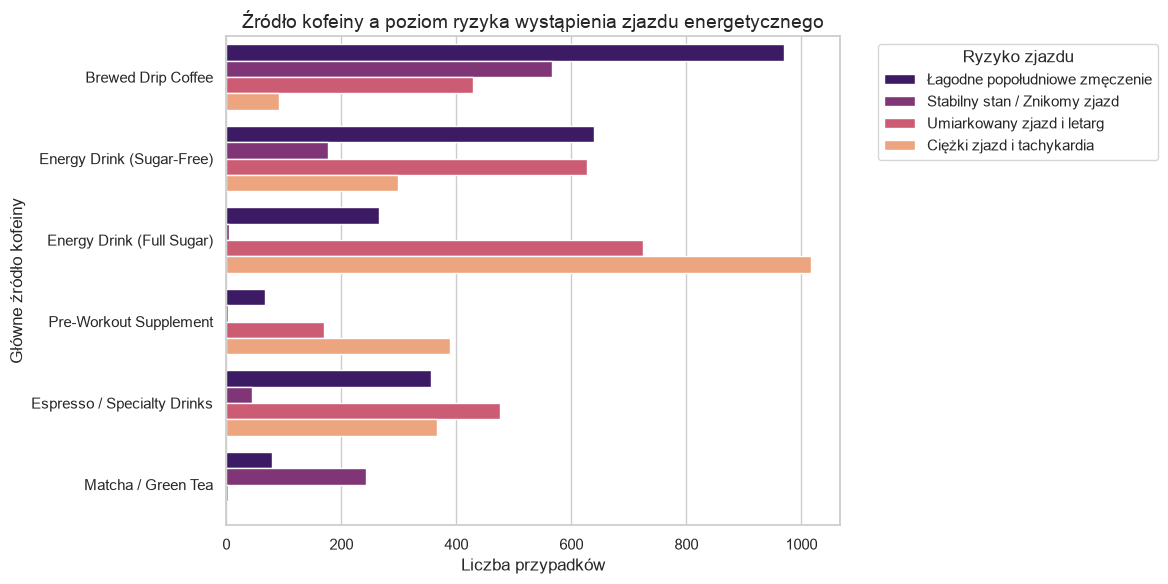

In [64]:
# Pokaże, które źródło kofeiny najczęściej powoduje ciężkie zjazdy
plt.figure(figsize=(12, 6))
sns.countplot(data=df, y='zrodlo_kofeiny', hue='poziom_ryzyka_zjazdu', palette='magma')
plt.title("Źródło kofeiny a poziom ryzyka wystąpienia zjazdu energetycznego", fontsize=14)
plt.xlabel("Liczba przypadków")
plt.ylabel("Główne źródło kofeiny")
plt.legend(title="Ryzyko zjazdu", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### WYKRES 6: Godziny snu vs Ostry poziom lęku (Regresji)

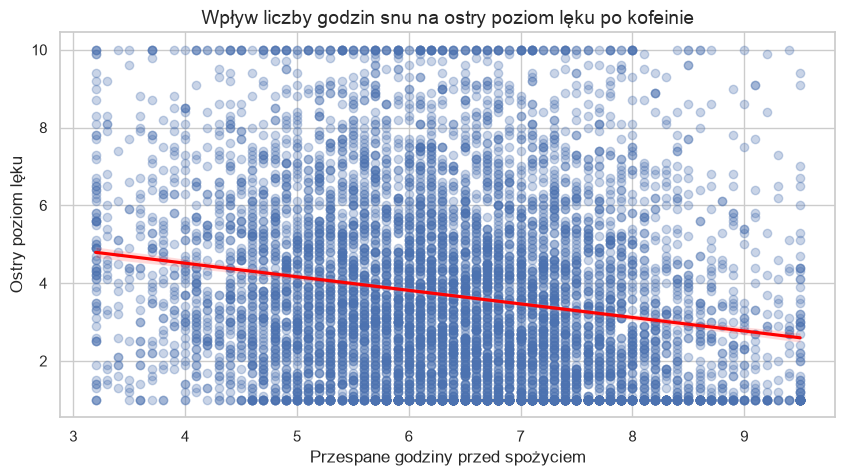

In [65]:
# Pokaże, czy krótki sen potęguje lęk po spożyciu kofeiny
plt.figure(figsize=(10, 5))
sns.regplot(data=df, x='godziny_snu', y='ostry_poziom_leku', scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title("Wpływ liczby godzin snu na ostry poziom lęku po kofeinie", fontsize=14)
plt.xlabel("Przespane godziny przed spożyciem")
plt.ylabel("Ostry poziom lęku")
plt.show()

## 3. Podział danych

### 1. Podział na trening i test

In [75]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#### 1. Wybieramy cechy wejściowe (X) oraz to, co chcemy przewidywać (y)

In [76]:
kolumny_numeryczne = [
    'wiek', 'bazowy_poziom_leku', 'godziny_snu', 'dzienne_nawodnienie_litry', 
    'kofeina_mg', 'cukier_gramy', 'czas_konsumpcji_min', 'intensywnosc_drzawek', 
    'ostry_poziom_leku', 'czas_do_zjazdu_godziny', 'nasilenie_zjazdu'
]

kolumny_tekstowe = [
    'plec', 'typ_metabolizmu_cyp1a2', 'tolerancja_kofeiny', 
    'zrodlo_kofeiny', 'poziom_ryzyka_zjazdu'
]

X_surowe = df[kolumny_numeryczne + kolumny_tekstowe]

y = df['skok_tetna_bpm']

#### 2. Zamienia kolumny tekstowe na kolumny z wartościami 0 i 1

In [77]:
X = pd.get_dummies(X_surowe, drop_first=True)
print(f"Liczba cech po zakodowaniu tekstu: {X.shape[1]}")

Liczba cech po zakodowaniu tekstu: 25


#### 3. Podział danych na zbiór treningowy (80%) i testowy (20%)
random_state=42 sprawia, że podział będzie zawsze taki sam

In [78]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#### 4. Sprawdzenie, czy wszystko podzieliło się poprawnie

In [79]:
print(f"Wszystkich próbek w X: {X.shape}")
print(f"Próbki treningowe (X_train): {X_train.shape[0]} wierszy")
print(f"Próbki testowe (X_test): {X_test.shape[0]} wierszy")

Wszystkich próbek w X: (8000, 25)
Próbki treningowe (X_train): 6400 wierszy
Próbki testowe (X_test): 1600 wierszy


#### 5. Skalowanie danych (Standaryzacja)
Sprawia, że wszystkie cechy (zarówno dawki w mg, jak i binarne 0/1) mają odpowiednią wagę dla modeli

In [86]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nDane zostały podzielone i wyskalowane")
print(f"Rozmiar X_train_scaled: {X_train_scaled.shape}")
print(f"Rozmiar X_test_scaled: {X_test_scaled.shape}")


Dane zostały podzielone i wyskalowane
Rozmiar X_train_scaled: (6400, 25)
Rozmiar X_test_scaled: (1600, 25)


## 4. Budowanie modeli

In [87]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, r2_score

### 1. Słownik wykorzystanych modelów

In [102]:
modele = {
    "1. Regresja Liniowa": LinearRegression(),
    "2. K-Nearest Neighbors (KNN)": KNeighborsRegressor(n_neighbors=9, weights='distance'),
    "3. Drzewo Decyzyjne": DecisionTreeRegressor(max_depth=8, random_state=42),
    "4. Las Losowy": RandomForestRegressor(n_estimators=200, max_depth=8, min_samples_split=5, random_state=42),
    "5. Support Vector Regressor (SVR)": SVR(C=10.0, kernel='rbf', epsilon=0.1)
}

### 2. Pętla trenująca i testująca każdy model po kolei

In [103]:
wyniki = []

for nazwa, model in modele.items():
    # Trening na danych wyskalowanych
    model.fit(X_train_scaled, y_train)
    
    # Predykcja na zbiorze testowym
    y_pred = model.predict(X_test_scaled)
    
    # Metryki oceny jakości
    mae = mean_absolute_error(y_test, y_pred) 
    r2 = r2_score(y_test, y_pred)             
    
    wyniki.append({"Model": nazwa, "MAE (Błąd)": mae, "R2 (Skuteczność)": r2})
    print(f"{nazwa} ukończony - MAE: {mae:.3f} | R²: {r2:.3f}")

1. Regresja Liniowa ukończony - MAE: 1.815 | R²: 0.644
2. K-Nearest Neighbors (KNN) ukończony - MAE: 1.763 | R²: 0.631
3. Drzewo Decyzyjne ukończony - MAE: 1.627 | R²: 0.653
4. Las Losowy ukończony - MAE: 1.481 | R²: 0.740
5. Support Vector Regressor (SVR) ukończony - MAE: 1.534 | R²: 0.707


### 3. Podsumowanie

* Las losowy to zbiór wielu drzew decyzyjnych głosujących wspólnie, z których każde uczy się na innej podgrupie danych. Doskonale radzi sobie z wyłapywaniem skomplikowanych, nieliniowych zależności i nie ulega tak łatwo pojedynczym błędom
* SVR szuka hiperpłaszczyzny z zachowaniem marginesu błędu (epsilon) w wielowymiarowej przestrzeni. Radzi sobie świetnie z danymi ciągłymi, ale bywa wolniejszy w trenowaniu przy dużych zbiorach
* Regresja liniowa szuka prostej zależności matematycznej między zmiennymi
* KNN patrzy na $K$ najbliższych sąsiadów na wykresie i wyciąga z nich średnią (po tym, jak dodano kolumny tekstowe za pomocą mapowania na 0 i 1, przestrzeń stała się bardzo "rozrzedzona", przez co pojęcie odległości między punktami traci na precyzji)
* Pojedyncze drzewo zadaje pytania typu "tak/nie", tworząc strukturę gałęzi (bez ograniczeń głębokości potrafi boleśnie się "przeuczyć" (overfitting))

In [104]:
tabela_wynikow = pd.DataFrame(wyniki)
display(tabela_wynikow.sort_values(by="R2 (Skuteczność)", ascending=False))

,Model,MAE (Błąd),R2 (Skuteczność)
3,4. Las Losowy,1.481469,0.739805
4,5. Support Vector Regressor (SVR),1.534059,0.707089
2,3. Drzewo Decyzyjne,1.626846,0.653192
0,1. Regresja Liniowa,1.814893,0.644421
1,2. K-Nearest Neighbors (KNN),1.762525,0.630817


## 5. Zapis najlepszego modelu

In [107]:
import joblib

### 1. Upewniamy się, że nasz najlepszy model jest wytrenowany na pełnym zbiorze treningowym

In [109]:
najlepszy_model = RandomForestRegressor(
    n_estimators=200, 
    max_depth=10, 
    min_samples_split=5, 
    random_state=42
)

### 2. Trenujemy model na wyskalowanych danych treningowych

In [110]:
najlepszy_model.fit(X_train_scaled, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

### 3. Zapisujemy model do pliku na dysku

In [112]:
plik_modelu = "model_skok_tetna.joblib"
joblib.dump(najlepszy_model, plik_modelu)
print(f"Model został zapisany w pliku: {plik_modelu}")
joblib.dump(scaler, "scaler_kofeina.joblib")
print("Scaler również został pomyślnie zapisany!")

Model został zapisany w pliku: model_skok_tetna.joblib
Scaler również został pomyślnie zapisany!


## 6. Test na własnych danych

### 1. Wczytujemy z dysku zapisany wcześniej model oraz scalar

In [113]:
model_wczytany = joblib.load("model_skok_tetna.joblib")
scaler_wczytany = joblib.load("scaler_kofeina.joblib")

### 2. Definiujemy dane nowego użytkownika

In [115]:
moje_dane = {
    'wiek': [30],
    'bazowy_poziom_leku': [3.0],
    'godziny_snu': [6],
    'dzienne_nawodnienie_litry': [4],
    'kofeina_mg': [200],                 
    'sugar_grams': [10.0],
    'czas_konsumpcji_min': [120],
    'intensywnosc_drzawek': [2.0],
    'ostry_poziom_leku': [1.5],
    'czas_do_zjazdu_godziny': [4.0],
    'nasilenie_zjazdu': [5.0],
    'plec': ['Male'],                    
    'typ_metabolizmu_cyp1a2': ['Fast'],
    'tolerancja_kofeiny': ['High'],  
    'zrodlo_kofeiny': ['Energy Drink (Sugar-Free)'], 
    'poziom_ryzyka_zjazdu': ['Mild Afternoon Fatigue']
}

### 3. Zamieniamy słownik na ramkę danych Pandas

In [116]:
df_nowy = pd.DataFrame(moje_dane)

### 4. Musimy wykonać dokładnie takie samo kodowanie jak na treningu
Najprościej zrobić to, wczytując kolumny z oryginalnego df i dopasowując kolumny (lub używając gotowej struktury X, na której trenowaliśmy model).

In [119]:
X_kolumny_wzorek = X.columns 

### 5. Robimy get_dummies dla nowych danych

In [120]:
df_nowy_zakodowany = pd.get_dummies(df_nowy)

### 6. Wyrównujemy kolumny, żeby nowe dane miały dokładnie taki sam zestaw kolumn co zbiór treningowy

In [121]:
df_nowy_zakodowany = df_nowy_zakodowany.reindex(columns=X_kolumny_wzorek, fill_value=0)

### 7. Skalujemy dane za pomocą naszego zapisanego wcześniej scalera

In [122]:
df_nowy_skalowany = scaler_wczytany.transform(df_nowy_zakodowany)

### 8. Wykonujemy predykcje

In [123]:
przewidziany_skok_tetna = model_wczytany.predict(df_nowy_skalowany)

In [124]:
print("=" * 50)
print(f"☕ WYNIK TESTU DLA NOWEGO UŻYTKOWNIKA:")
print(f"Przewidywany skok tętna: {przewidziany_skok_tetna[0]:.2f} bpm (uderzeń na minutę)")
print("=" * 50)

☕ WYNIK TESTU DLA NOWEGO UŻYTKOWNIKA:
Przewidywany skok tętna: 2.15 bpm (uderzeń na minutę)
